# Plots

`fl.plot` draws experiment logs with matplotlib. It has three functions:

- `fl.plot.curve`: learning curves along the stream, against the number of instances or the cost
  spent;
- `fl.plot.budget`: a metric against the budget, for setups run with several budgets;
- `fl.plot.queries`: how often each output is queried along the stream.

The plotted values come from `fl.metrics`, so a plot always shows the same numbers as the
metrics. Every function returns the axes it drew on, so you can change the plot afterwards with
matplotlib.

This notebook uses one setting for all the plots: a stream with three outputs, where one of them
drifts halfway through.

In [1]:
from river import metrics, multioutput, neighbors, utils

import fishladder as fl

## The experiment

The stream comes from `fl.synth.MultiTarget`. Output `y1` changes suddenly after 2000
instances, and `y0` and `y2` do not. All outputs cost 1, and a shared budget of 0.6 per instance
pays for 20% of the labels.

The model is a nearest neighbours regressor per output, which only remembers the last 200 labels
it learned from. It can only follow the drift if `y1` gets new labels. We compare three setups:

- **all labels**: every output is queried on every instance, which gives an upper bound;
- **random**: each output is queried as soon as the budget allows it;
- **expected error**: the budget goes to the outputs on which the model is expected to make the
  largest error. With a shared budget, its utilities decide which outputs get the labels, so it
  needs no `fl.budget.VariableThreshold`.

Each budgeted setup is run with three seeds, each on a different stream.

In [2]:
DRIFT = 2000
COSTS = {"y0": 1.0, "y1": 1.0, "y2": 1.0}
SEEDS = [0, 1, 2]


def stream(seed):
    dataset = fl.synth.MultiTarget(
        n_features=3, correlation=0.3, noise=0.1, drift={"y1": DRIFT}, seed=seed
    )
    return dataset.take(2 * DRIFT)


def knn():
    return neighbors.KNNRegressor(engine=neighbors.LazySearch(window_size=200))


def run(setup, rate, seed):
    strategy = {
        "all labels": fl.strategy.QueryAll(),
        "random": fl.strategy.RandomPerOutput(p=1.0, seed=seed),
        "expected error": fl.strategy.ExpectedError(knn()),
    }[setup]
    budget = fl.budget.Unlimited() if setup == "all labels" else fl.budget.RateBudget(rate)
    model = multioutput.PerOutputRegressor(knn())
    return fl.evaluate.prequential(stream(seed), model, strategy, budget, COSTS)


runs = {
    "random": [run("random", 0.6, seed) for seed in SEEDS],
    "expected error": [run("expected error", 0.6, seed) for seed in SEEDS],
    "all labels": [run("all labels", None, seed) for seed in SEEDS],
}

## Runs and repeats

A run is either one log, or a list of logs of the same setup, such as different seeds. For a
list, the plots draw the mean over the logs, and shade the range between the lowest and highest
values. This range shows how much the logs differ. It is not a confidence interval: with three
seeds, it is only what we happened to see. To compare setups, pass a dictionary of runs by name.

## Learning curves

`fl.plot.curve` draws one panel per output. Wrapping the metric in River's `utils.Rolling` shows
the error over the last instances, which makes the drift visible. The cumulative error of the
whole past would hide it.

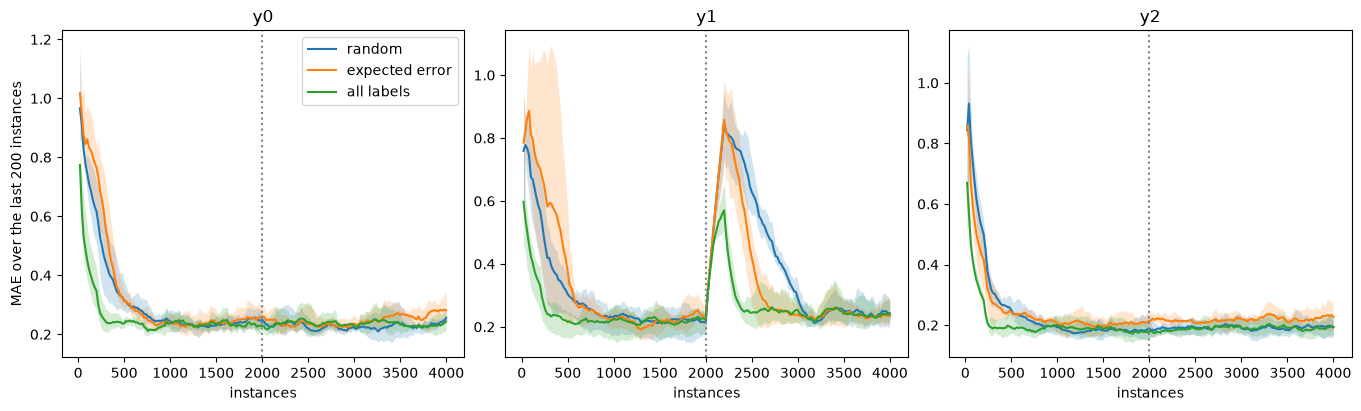

In [3]:
mae = utils.Rolling(metrics.MAE, window_size=200)

axes = fl.plot.curve(runs, mae, every=20)
for ax in axes:
    ax.axvline(DRIFT, color="grey", linestyle=":")
axes[0].set_ylabel("MAE over the last 200 instances");

The error on `y1` jumps at the drift. Expected error recovers faster than random querying,
because it moves labels to `y1`. With all labels, the model recovers fastest, since it gets every
label of `y1`. At the start of the stream, expected error is behind on `y1`: its error models
have few labels to learn from yet.

`every=20` computes a point every 20 instances, which is faster on long streams. With several
seeds, the curves are interpolated to the same x values before the mean is taken.

## Against the cost spent

With `x="cost"`, the curves are drawn against the cost spent, so setups are compared at the same
number of labels. Here, `every` is in cost: each run gets a point each time it has spent 20 more,
so all runs have points at the same costs.

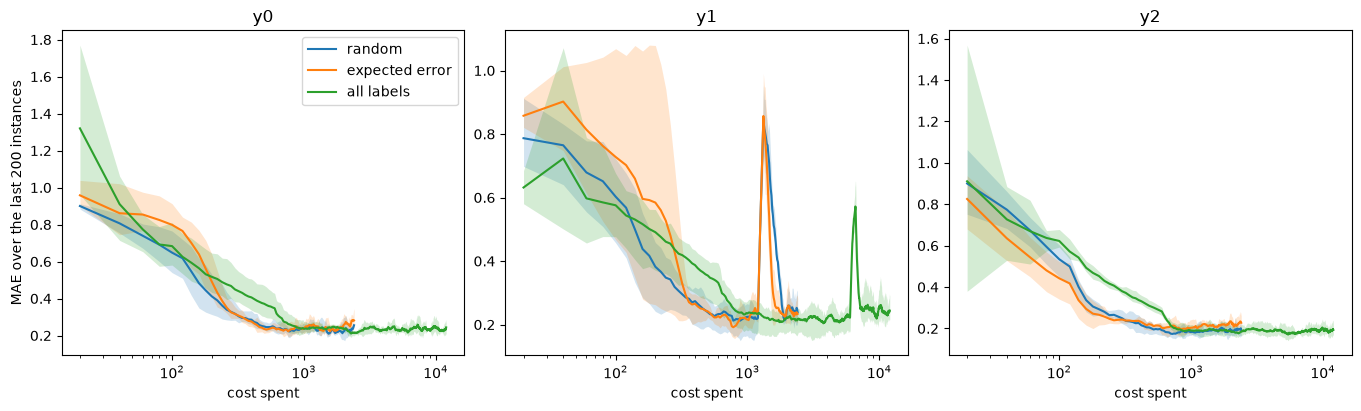

In [4]:
axes = fl.plot.curve(runs, mae, x="cost", every=20)
for ax in axes:
    ax.set(xscale="log")
axes[0].set_ylabel("MAE over the last 200 instances");

All runs start at the same cost, and end at the cost they spent in total. With all labels, the
runs spend 3 per instance against 0.6, so their curves go five times further to the right. At
the same cost, though, they have seen five times fewer instances: all labels is an upper bound at
the same point in the stream, not at the same cost.

With `average=True`, the metric is averaged over the outputs, in a single panel:

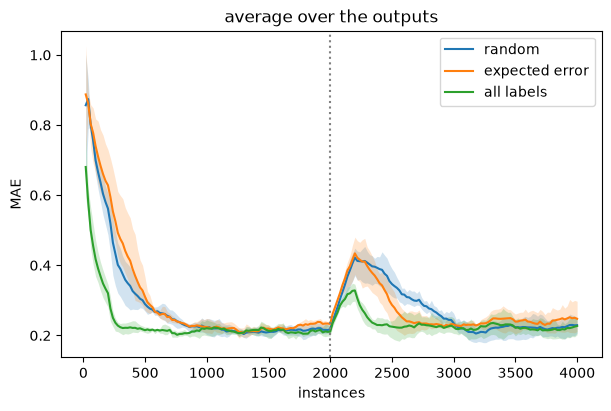

In [5]:
fl.plot.curve(runs, mae, every=20, average=True).axvline(DRIFT, color="grey", linestyle=":");

## Difference to a baseline

When setups are close, their lines lie on top of each other. With `baseline`, each run is drawn
minus the mean of the baseline. The baseline is then drawn at 0, with the range of its own logs
around it. Below 0 means a lower error than the baseline.

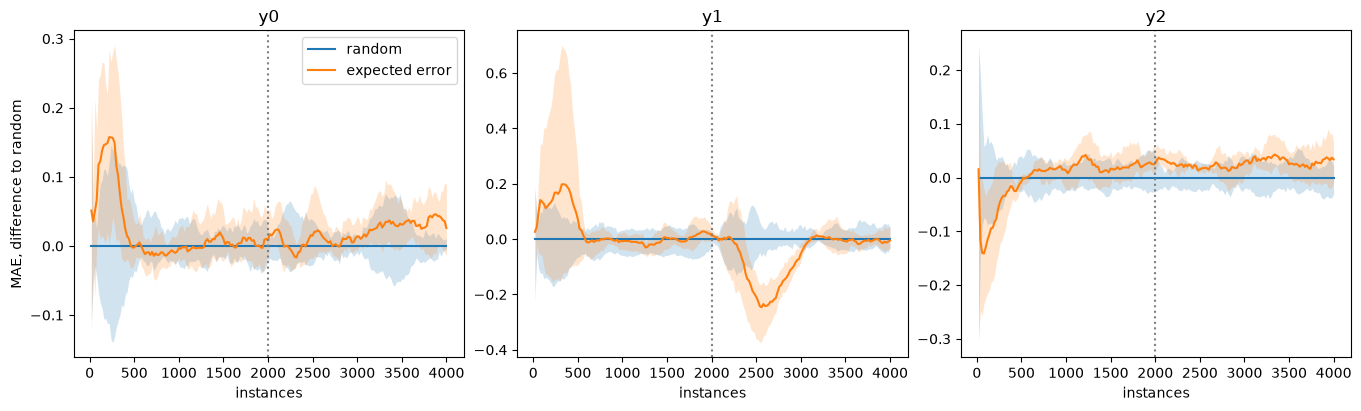

In [6]:
budgeted = {name: runs[name] for name in ["random", "expected error"]}  # same colours as above
axes = fl.plot.curve(budgeted, mae, every=20, baseline="random")
for ax in axes:
    ax.axvline(DRIFT, color="grey", linestyle=":")

After the drift, expected error is much better than random querying on `y1`, by up to 0.25.
It pays for this elsewhere: it is worse on `y2` for most of the stream, on `y0` near the end, and
on `y0` and `y1` in the first 500 instances. Where its line is inside the band of random, the
difference is no larger than the spread between the seeds of random.

## Queries

`fl.plot.queries` shows the share of instances on which each output is queried, over a moving
window. The panels share their y axis.

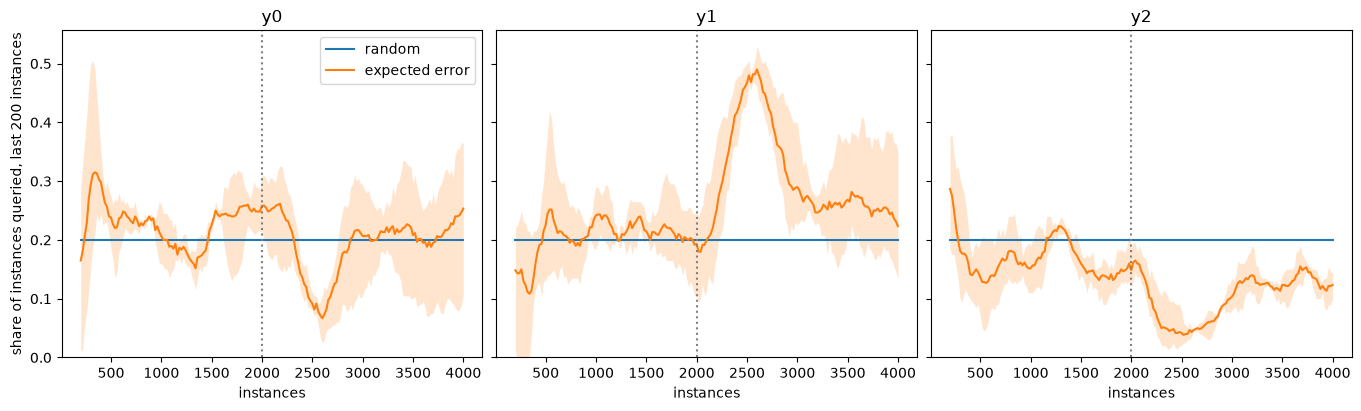

In [7]:
axes = fl.plot.queries(budgeted, window=200)
for ax in axes:
    ax.axvline(DRIFT, color="grey", linestyle=":")

Random querying queries each output on 20% of the instances, a third of the budget, all along
the stream. Expected error moves most of the budget to `y1` right after the drift, taking it from
`y0` and `y2`, then gives part of it back as the error on `y1` goes down.

With `cost=True`, the plot shows the cost spent instead, which is useful when outputs have
different costs.

## Comparing budgets

To see how setups do with more or less budget, run them with several budgets, and pass a list of
runs per setup, one per budget, to `fl.plot.budget`. Each run gives one point: the value of the
metric over the whole stream, and the cost the run really spent, read from the log.

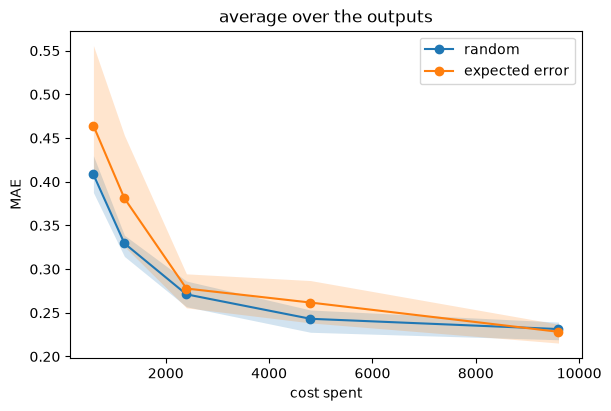

In [8]:
RATES = [0.15, 0.3, 0.6, 1.2, 2.4]


def budget_axis(ax):
    # A log x axis with a tick at each budget
    ax.set_xscale("log")
    ax.set_xticks(RATES, [f"{rate:g}" for rate in RATES])
    ax.minorticks_off()
    ax.set_xlabel("budget per instance")


by_budget = {
    setup: [[run(setup, rate, seed) for seed in SEEDS] for rate in RATES]
    for setup in ["random", "expected error"]
}
fl.plot.budget(by_budget, metrics.MAE(), average=True);

Over the whole stream, expected error is not better than random querying here, and at low
budgets it differs much more between seeds. Its gain on `y1` after the drift lasts a few hundred
instances, while its losses at the start of the stream and on the other outputs add up.

With `budgets`, the runs are drawn at their budget instead. This is clearer when all setups spend
their whole budget. With a dictionary, each setup can have its own budgets.

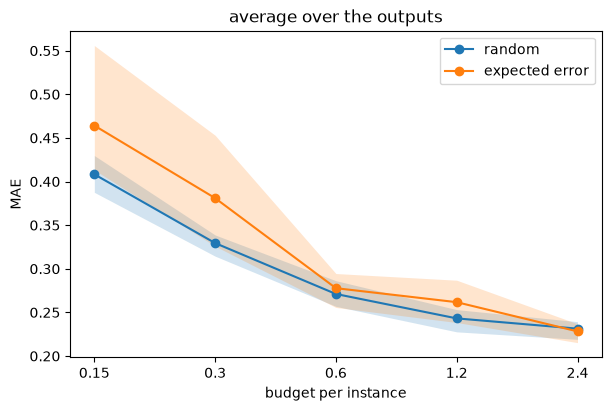

In [9]:
budget_axis(fl.plot.budget(by_budget, metrics.MAE(), budgets=RATES, average=True))

`baseline` works here too, and `summary="auc"` gives the area under the learning curve against
the cost, instead of the final value. The area also counts how fast the error goes down, and how
fast it recovers from the drift.

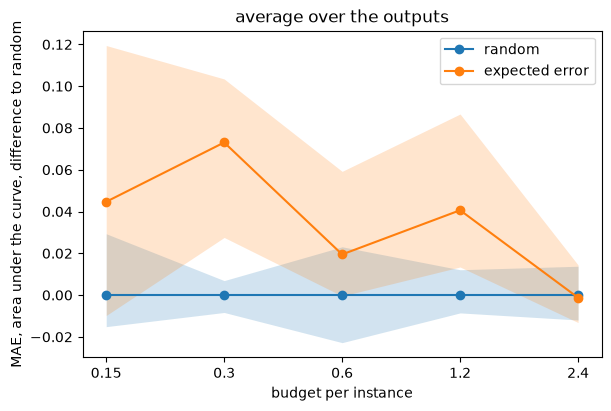

In [10]:
budget_axis(
    fl.plot.budget(
        by_budget, metrics.MAE(), budgets=RATES, average=True, baseline="random", summary="auc"
    )
)

The upper bound, all labels, has a single budget. To draw it as a line across the plot, use
matplotlib on the axes that `fl.plot.budget` returns. Here, the line is the mean over its three
seeds, one panel per output:

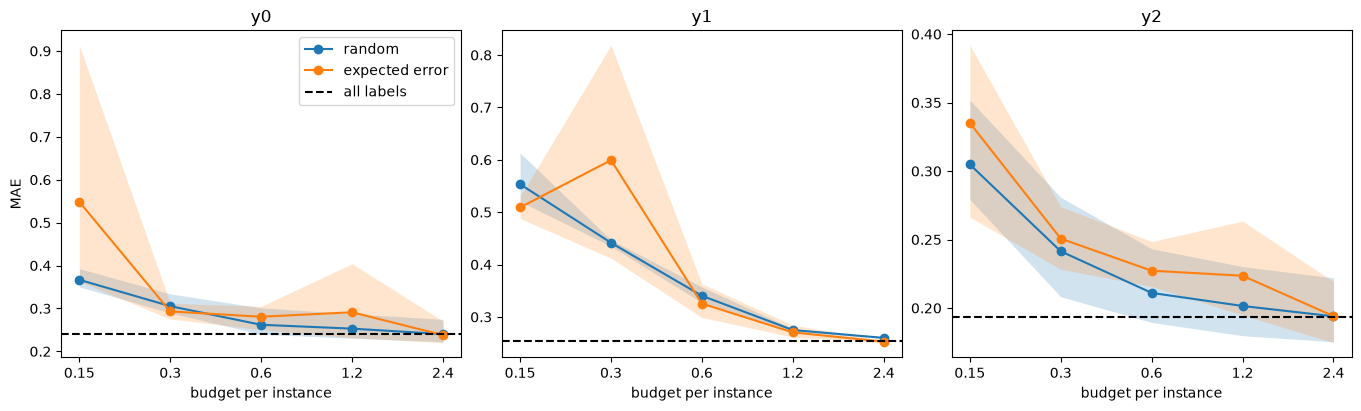

In [11]:
import numpy as np

axes = fl.plot.budget(by_budget, metrics.MAE(), budgets=RATES)
full = [fl.metrics.per_output(log, metrics.MAE()) for log in runs["all labels"]]
for ax in axes:
    output = ax.get_title()
    value = np.mean([metric[output].get() for metric in full])
    ax.axhline(value, color="black", linestyle="--", label="all labels")
    budget_axis(ax)
axes[0].legend();